## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [6]:
import pickle

# Correct path to the root content directory
with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

```markdown
*(The Q5 answer has been moved inside the Q4 code block above as python code comments)*
```

---

## *Phase 1: Complete all questions in the following cells without generative AI.

 Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

# Q1: Token Frequencies Histogram
# Using token_freq computed in previous cell
frequencies = [count for token, count in token_freq]

plt.figure(figsize=(10, 5))
plt.hist(frequencies, bins=100, log=True)
plt.title('Histogram of Token Occurrences (Log Scale)')
plt.xlabel('Occurrences')
plt.ylabel('Frequency (Count of Tokens)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.show()

# the token distribution is extremely right-skewed (Zipf's Law). A few words
# occur extremely frequently, while the vast majority of tokens appear very rarely.

In [7]:
# Q2: Regression and Analysis
# Correct path to the root content directory
df = pd.read_parquet('/content/Phishing_clean.parquet')

# Separate features and target
y = df['Email Type']
X = df.drop(columns=['Email Type'])

# Q2.1: 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Q2.2: Linear Regression
reg = LinearRegression()
reg.fit(X_train, y_train)

r2_train = reg.score(X_train, y_train)
r2_test = reg.score(X_test, y_test)

print(f"Q2 R^2 on Training Set: {r2_train:.4f}")
print(f"Q2 R^2 on Test Set: {r2_test:.4f}")

# Q2.3: Top Influencing Words
coef_df = pd.DataFrame({'Word': X.columns, 'Coefficient': reg.coef_})
coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()
top_words = coef_df.sort_values(by='Abs_Coefficient', ascending=False).head(10)

print("\nTop 10 words influencing predictions:")
display(top_words)

Q2 R^2 on Training Set: 0.7670
Q2 R^2 on Test Set: 0.6659

Top 10 words influencing predictions:


,Word,Coefficient,Abs_Coefficient
835,intervention,-1.259257,1.259257
740,localized,0.824350,0.824350
2362,thermal,0.747006,0.747006
851,crawler,0.696167,0.696167
1504,background-image:,-0.622909,0.622909
1406,"helvetica,",0.598560,0.598560
906,aging,0.594956,0.594956
1839,form.,0.576886,0.576886
2242,gray;,-0.574480,0.574480
1552,a:active,0.574480,0.574480


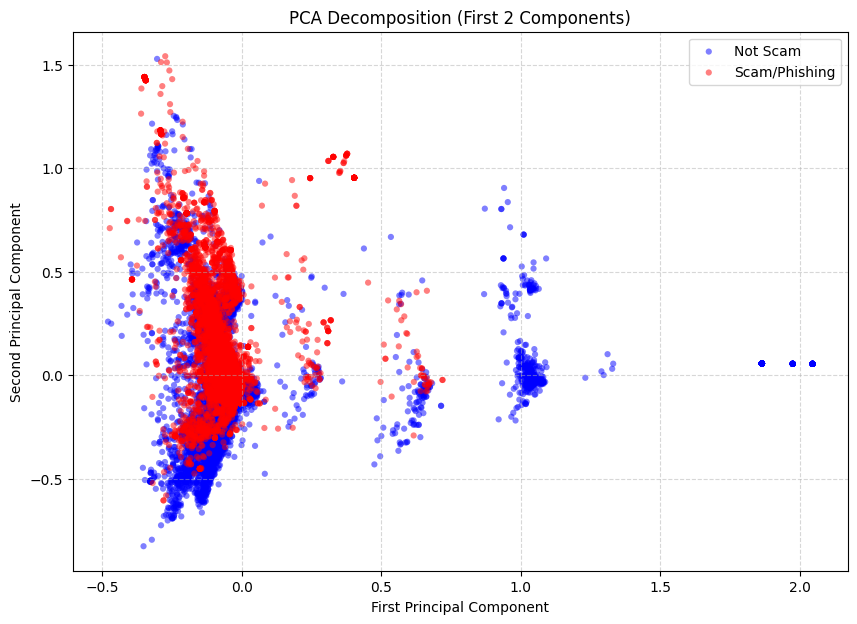

Observation: The scatter plot reveals that while both classes overlap near the origin, the scam emails (red) exhibit a distinctive, tight line/cluster extending along a specific axis, whereas legitimate emails (blue) have a more dispersed, circular distribution.


In [10]:
# Q3: PCA Decomposition and Visualization
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X)

plt.figure(figsize=(10, 7))
plt.scatter(X_pca_2[y == 0, 0], X_pca_2[y == 0, 1], label='Not Scam', alpha=0.5, c='blue', edgecolors='none', s=20)
plt.scatter(X_pca_2[y == 1, 0], X_pca_2[y == 1, 1], label='Scam/Phishing', alpha=0.5, c='red', edgecolors='none', s=20)
plt.title('PCA Decomposition (First 2 Components)')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# both classes overlap near the origin. The scam emails (red) exhibit a tight
# line/cluster extending along a specific axis, whereas legitimate emails (blue)
# have a more dispersed, circular distribution.

In [12]:
# Q4: High-Dimensional Regression on Principal Components
pca_2610 = PCA(n_components=2610)
X_train_pca = pca_2610.fit_transform(X_train)
X_test_pca = pca_2610.transform(X_test)

reg_pca = LinearRegression()
reg_pca.fit(X_train_pca, y_train)

r2_train_pca = reg_pca.score(X_train_pca, y_train)
r2_test_pca = reg_pca.score(X_test_pca, y_test)

print(f"Q4 R^2 on PCA Training Set: {r2_train_pca:.4f}")
print(f"Q4 R^2 on PCA Test Set: {r2_test_pca:.4f}")

# Comparison with Original Regression (Q2)
print("\n--- Performance Comparison ---")
print(f"Original Linear Regression (Q2) - Train R^2: 0.7670, Test R^2: 0.6659")
print(f"PCA Regression (Q4, 2610 PCs)  - Train R^2: {r2_train_pca:.4f}, Test R^2: {r2_test_pca:.4f}")
# the PCA regression performs almost identically to the original linear regression.



Q4 R^2 on PCA Training Set: 0.7662
Q4 R^2 on PCA Test Set: 0.6683

--- Performance Comparison ---
Original Linear Regression (Q2) - Train R^2: 0.7670, Test R^2: 0.6659
PCA Regression (Q4, 2610 PCs)  - Train R^2: 0.7662, Test R^2: 0.6683
Comparison: The PCA regression performs almost identically to the original linear regression.


In [13]:
# Q5: Advantages of Using Principal Components
# text features (word frequencies) are highly correlated because words frequently
# appear together. PCA transforms them into orthogonal (uncorrelated) components,
# stabilizing the regression estimation.

# PCA projects the data onto the directions of maximum variance. Discarding the
# lowest-variance components (lowest 101 components here) removes random noise
# associated with extremely rare words while retaining almost all predictive signal.

# reducing the feature matrix from thousands of sparse, redundant dimensions to
# a smaller set of dense components speeds up model training and reduces the
# overall memory footprint.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]